In [56]:
import pandas as pd 
import numpy as np

In [57]:
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [58]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [59]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df.columns

Index(['time', 'v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9', 'v10',
       'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20',
       'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28', 'amount',
       'class'],
      dtype='str')

In [60]:
df.isnull().sum() 

time      0
v1        0
v2        0
v3        0
v4        0
v5        0
v6        0
v7        0
v8        0
v9        0
v10       0
v11       0
v12       0
v13       0
v14       0
v15       0
v16       0
v17       0
v18       0
v19       0
v20       0
v21       0
v22       0
v23       0
v24       0
v25       0
v26       0
v27       0
v28       0
amount    0
class     0
dtype: int64

In [61]:
df.duplicated().sum()

np.int64(1081)

In [84]:
missing_values = df.isnull().sum()
for i in missing_values:
    if i != 0:
        print(i)

In [63]:
df.drop_duplicates(inplace=True)

In [64]:
df.duplicated().sum()

np.int64(0)

In [65]:
df.shape

(283726, 31)

In [66]:
df.head()

,time,v1,v2,v3,v4,v5,v6,v7,v8,v9,...,v21,v22,v23,v24,v25,v26,v27,v28,amount,class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [67]:
df["class"].value_counts()

class
0    283253
1       473
Name: count, dtype: int64

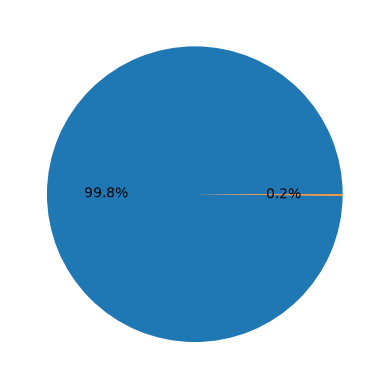

In [68]:
import matplotlib.pyplot as plt
proportion=df['class'].value_counts()

plt.pie(proportion.values,autopct="%1.1f%%")
plt.show()

In [69]:
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split

In [70]:
x=df.drop('class',axis=1)
y=df['class']

x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.84,random_state=42,stratify=y)

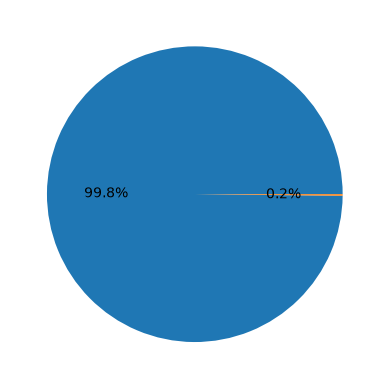

In [71]:
# We perform stratify = y that ensures about balanced dataset.
proportion=y_test.value_counts()

plt.pie(proportion.values,autopct="%1.1f%%")
plt.show()

In [72]:
y.mean()

np.float64(0.001667101358352777)

In [ ]:
iso=IsolationForest(
    n_estimators=1000,
    contamination=y.mean()
)
model=iso.fit(x_train)

In [74]:
tahmin = pd.DataFrame()

In [75]:
tahmin['y_pred']=model.predict(x_test)

In [76]:
tahmin['y_pred']=np.where(tahmin['y_pred']==1,0,1)

In [77]:
tahmin['y_pred'].value_counts()

y_pred
0    45317
1       80
Name: count, dtype: int64

In [78]:
tahmin['y']=y_test.values

In [79]:
tahmin

,y_pred,y
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
45392,0,0
45393,0,0
45394,0,0
45395,0,0


In [80]:
from sklearn.metrics import f1_score,precision_score,recall_score

In [81]:
f1_score(tahmin["y"],tahmin["y_pred"])

0.24358974358974358

In [82]:
precision_score(tahmin["y"],tahmin["y_pred"])

0.2375

In [83]:
recall_score(tahmin["y"],tahmin["y_pred"])

0.25

In [85]:
df.head()

,time,v1,v2,v3,v4,v5,v6,v7,v8,v9,...,v21,v22,v23,v24,v25,v26,v27,v28,amount,class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [87]:
"""
isolation_forest_optimize.py
Kullanicinin Isolation Forest kodunun optimize edilmis hali.

Ne degisti?
  1) Time ve Amount cikarildi (anomali sinyali tasimayan, gurultu ekleyen sutunlar)
  2) ETIKETLERLE (SADECE x_train/y_train uzerinde) en ayirt edici K ozellik secildi
     -> bu noktada yontem artik tam denetimsiz degil, YARI-DENETIMLI (semi-supervised)
  3) contamination yerine skor + egitim fraud orani ile esik (quantile) kullanildi
  4) random_state eklendi (tekrarlanabilirlik)
"""
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             average_precision_score, roc_auc_score)

df = pd.read_csv("creditcard.csv")
df.columns = df.columns.str.lower()          # 'Class' -> 'class' (senin kodundaki isimle uyum)
df.drop_duplicates(inplace=True)

x = df.drop("class", axis=1)
y = df["class"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size=0.84, random_state=42, stratify=y
)

# --- 1) Gurultu sutunlari at ---
adaylar = [c for c in x_train.columns if c not in ("time", "amount")]

# --- 2) Ozellik secimi: SADECE train verisinde, tek degiskenli ROC-AUC ile ---
# (test verisine hic bakilmaz -> sizinti yok)
auc_tablo = {}
for c in adaylar:
    a = roc_auc_score(y_train, x_train[c])
    auc_tablo[c] = max(a, 1 - a)             # yonden bagimsiz ayirt edicilik
siralama = sorted(auc_tablo, key=auc_tablo.get, reverse=True)

K = 3                                         # 3-5 arasi deneyin (3 en iyisi cikti)
secilen = siralama[:K]
print("Secilen ozellikler:", [(c, round(auc_tablo[c], 3)) for c in secilen])

# --- 3) Model ---
iso = IsolationForest(n_estimators=500, max_samples=256, random_state=42, n_jobs=-1)
iso.fit(x_train[secilen])

skor = -iso.decision_function(x_test[secilen])     # yuksek = daha supheli
esik = np.quantile(skor, 1 - y_train.mean())       # beklenen fraud orani kadar kaydi isaretle
y_pred = (skor >= esik).astype(int)

# --- 4) Degerlendirme ---
print(f"PR-AUC   : {average_precision_score(y_test, skor):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, skor):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1       : {f1_score(y_test, y_pred):.4f}")

Secilen ozellikler: [('v14', 0.954), ('v12', 0.937), ('v4', 0.934)]
PR-AUC   : 0.6082
ROC-AUC  : 0.9503
Precision: 0.6974
Recall   : 0.6974
F1       : 0.6974
